# Surface exciton-polaritons in J-aggregate gratings

TM scattering by a one-dimensional grating of anisotropic polarizable ribbons placed on a dielectric
spacer above a Drude metal. The notebook reproduces every figure of the paper and the additional
results given in the reply to the referees. See `README.md` for an overview.

Run the cells in order. Figures are written to `figures/`.

In [1]:
import os
from contextlib import contextmanager, nullcontext

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.optimize import brentq, minimize, minimize_scalar
from scipy.signal import find_peaks
from scipy.ndimage import minimum_filter

FIGDIR = "figures"
FAST = False          # True: coarser (omega, d) maps in Fig. 8

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"], "mathtext.fontset": "dejavusans",
    "pdf.fonttype": 42, "ps.fonttype": 42,          # TrueType fonts in the PDFs (IOP requirement)
    "axes.labelsize": 10, "axes.linewidth": 1.0, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.fontsize": 8, "legend.frameon": True, "legend.edgecolor": "black",
    "legend.framealpha": 1.0, "legend.fancybox": False, "legend.borderpad": 0.4,
    "legend.handlelength": 1.7, "legend.labelspacing": 0.35, "lines.linewidth": 1.6,
    "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True, "ytick.right": True,
    "xtick.major.size": 4.5, "ytick.major.size": 4.5, "xtick.minor.size": 2.5, "ytick.minor.size": 2.5,
    "xtick.major.width": 1.0, "ytick.major.width": 1.0, "xtick.minor.width": 0.7, "ytick.minor.width": 0.7,
    "xtick.minor.visible": True, "ytick.minor.visible": True,
    "figure.dpi": 120, "path.simplify": False,
})

# figure sizes match the width they take in the paper (\textwidth = 153 mm)
MM = 1 / 25.4
FIG_WIDE = (107 * MM, 89 * MM)      # 0.70 \textwidth
FIG_PANEL = (73 * MM, 61 * MM)      # 0.48 \textwidth


def new_figure(size=FIG_WIDE, nbins=5):
    fig, ax = plt.subplots(figsize=size, layout="constrained")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(ticker.MaxNLocator(nbins=nbins, steps=[1, 2, 2.5, 5, 10]))
    return fig, ax


def save_figure(fig, name):
    os.makedirs(FIGDIR, exist_ok=True)
    fig.savefig(os.path.join(FIGDIR, name + ".pdf"))

## Model

### Parameters and susceptibility

SI units, time dependence $e^{-i\omega t}$. The polarizable sheet has a Lorentzian response with in-plane and
out-of-plane components weighted by $\cos^2\Psi$ and $\sin^2\Psi$, where $\Psi$ is the tilt angle of the dipoles.

In [2]:
eps1 = 2.3                  # region I (incidence)
eps2 = 2.3                  # region II (spacer)
epsb = 1                    # background permittivity of the polarizable layer
c = 299792458
hbar = 6.626e-34 / (2 * np.pi)
EV = 1.60218e-19 / hbar     # 1 eV in rad/s
wp = 1.37e16                # Drude plasma frequency (9 eV)
w0 = 3190.5e12              # exciton frequency (2.1 eV)
f0 = 10e-9                  # oscillator strength
N = 50                      # Bloch orders -N..N


def epsmetal(w):
    return 1 - wp**2 / w**2          # lossless Drude metal (see lossy_metal below)


# Csix carries an extra minus sign, which comes from the orientation of the cross
# product in the magnetic boundary condition; chi_parallel of the paper is -Csix.
def Csix(w):
    return -f0 * w0**2 * (np.cos(b)**2 / 2) / (w0**2 - w**2 - 2j * w * dpp) * factor


def Csiz(w):
    return f0 * w0**2 * np.sin(b)**2 / (w0**2 - w**2 - 2j * w * dpp) * factor

### Geometry

`configure()` sets the geometry and the material parameters that the functions below read as globals.
Called without arguments it restores the values of the paper: $R=70$ nm, $F=d_J/R=0.75$, $d=60$ nm,
$\Psi=15^\circ$, $\hbar\gamma_0=0.01$ eV. The ribbon edges are smoothed by a Gaussian of width $\sigma$ so that
the Fourier series of the susceptibility converges; $\sigma$ depends on the filling factor.

In [3]:
SIGMA_OVER_R = {0.25: 0.20, 0.50: 0.15, 0.75: 0.08, 0.80: 0.07, 0.85: 0.05, 0.90: 0.04}


def configure(R_nm=70.0, fill=0.75, sigma_over_R=None, d_nm=60.0,
              kasha_deg=15.0, factor_=1, homogeneous=False, dpp_=0.01):
    """homogeneous=True gives an unpatterned sheet (d0 = R); factor_=0 removes the layer."""
    global R, d0, sigma, d, b, factor, dpp
    R = R_nm * 1e-9
    d0 = R if homogeneous else fill * R
    if sigma_over_R is None:
        sigma_over_R = SIGMA_OVER_R.get(round(fill, 2), 0.15)
    sigma = sigma_over_R * R
    d = d_nm * 1e-9
    b = np.pi * kasha_deg / 180
    factor = factor_
    dpp = dpp_ * 1.60218e-19 / hbar


configure()

ws = np.linspace(0.8 * w0, 1.2 * w0, 1000)     # frequency grid used for all spectra
x = ws / w0


def window(lo, hi):
    """Points of ws (and x) with lo <= w/w0 <= hi."""
    keep = (x >= lo) & (x <= hi)
    return ws[keep], x[keep]

### Fourier coefficients of the ribbon susceptibility

Matrices $\chi_{n-l}$ for the in-plane (`XX`) and out-of-plane (`XZ`) components.

In [4]:
def _fourier(C):
    idx = np.arange(-N, N + 1)
    diff = idx[:, None] - idx[None, :]
    X = np.empty(diff.shape, dtype=np.complex64)
    X[diff == 0] = C * d0 / R
    mask = diff != 0
    m = diff[mask]
    G = 2 * np.pi / R
    y = m * G * d0 / 2
    X[mask] = C * (d0 / R * np.sin(y) / y) * np.exp(-(m * G * sigma)**2 / 2) * np.exp(-1j * m * G * R / 2)
    return X


def XX(w):
    return _fourier(Csix(w))


def XZ(w):
    return _fourier(Csiz(w))

### Out-of-plane wave-vectors and the linear system

`alpha`, `beta` and `gamma` contain the propagation direction: $\alpha_n=-i\kappa^{(1)}_n$,
$\beta_n=+i\kappa^{(2)}_n$, $\gamma_n=-i\kappa^{(3)}_n$, with $\mathrm{Im}\,\kappa\ge0$. `T_plus` and `T_minus` transfer the
spacer amplitudes to the metal interface. `M` and `B11`, `B21` are the matrix and the source term of
Eq. (21) of the paper, with the coefficients of regions I and III interleaved.

In [5]:
def q_orders(w, theta):
    q = np.sqrt(eps1) * w * np.sin(theta) / c
    return q + 2 * np.pi * np.arange(-N, N + 1) / R


def alpha(w, theta):
    return -1j * np.sqrt(eps1 * w**2 / c**2 - q_orders(w, theta)**2 + 0j)


def beta(w, theta):
    return 1j * np.sqrt(eps2 * w**2 / c**2 - q_orders(w, theta)**2 + 0j)


def gamma(w, theta):
    return -1j * np.sqrt(epsmetal(w) * w**2 / c**2 - q_orders(w, theta)**2 + 0j)


def T_plus(w, theta):
    g, bt, eps3 = gamma(w, theta), beta(w, theta), epsmetal(w)
    return np.exp((-g + bt) * d) * (1 / 2 + eps2 * g / (2 * eps3 * bt))


def T_minus(w, theta):
    g, bt, eps3 = gamma(w, theta), beta(w, theta), epsmetal(w)
    return np.exp((-g - bt) * d) * (1 / 2 - eps2 * g / (2 * eps3 * bt))


def kz(w, theta):
    q = np.sqrt(eps1) * w * np.sin(theta) / c
    return np.sqrt(eps1 * w**2 / c**2 - q**2)


def M(w, theta):
    kn = q_orders(w, theta)[:, None]
    kl = q_orders(w, theta)[None, :]
    a = alpha(w, theta)[None, :]
    bt = beta(w, theta)[None, :]
    Tp = T_plus(w, theta)[None, :]
    Tm = T_minus(w, theta)[None, :]
    Xx, Xz = XX(w), XZ(w)
    one = np.eye(2 * N + 1, dtype=np.complex64)

    m11 = (-a * one + 1 / (2 * epsb) * Xz * kl * kn) * (1 / eps1)
    m12 = (-(Tp - Tm) * bt * one + Xz * kl * kn / (2 * epsb) * (Tp + Tm)) * 1 / eps2
    m21 = -(1 / (2 * eps1)) * a * Xx + one
    m22 = -(Tp + Tm) * one + 1 / (2 * eps2) * Xx * bt * (Tp - Tm)

    big = np.zeros((2 * (2 * N + 1),) * 2, dtype=np.complex128)
    big[0::2, 0::2], big[0::2, 1::2] = m11, m12
    big[1::2, 0::2], big[1::2, 1::2] = m21, m22
    return big


def B11(w, theta):
    q = np.sqrt(eps1) * w * np.sin(theta) / c
    one = np.zeros(2 * N + 1); one[N] = 1
    return (1j * kz(w, theta) * one - XZ(w)[:, N] * q * q_orders(w, theta) / (2 * epsb)) * (1 / eps1)


def B21(w, theta):
    one = np.zeros(2 * N + 1); one[N] = 1
    return -one + XX(w)[:, N] * 1 / (2 * eps1) * kz(w, theta) * 1j

### Reflectance and absorptance

$\mathcal{R}$ sums the reflected orders that propagate in region I. $\mathcal{A}_\mathrm{m}$ is the power that enters
region III, evaluated at its surface $z=-d$ (the amplitudes $B^{(3)}_{y,n}$ are referred to $z=0$, hence the factor
$e^{i\kappa^{(3)}_n d}$), and $\mathcal{A}_\mathrm{J}=1-\mathcal{R}-\mathcal{A}_\mathrm{m}$ is the absorptance of the polarizable layer.
For a transparent region III, $\mathcal{A}_\mathrm{m}$ is the transmittance; for the lossless metal it vanishes. With a
lossy metal, $\mathcal{A}_\mathrm{m}$ is the absorptance of the metal.

In [6]:
def power_balance(w, theta=0.0):
    """(R, A_m, A_J) at angular frequency w and angle of incidence theta."""
    rhs = np.column_stack((B11(w, theta), B21(w, theta))).reshape(-1, 1)
    coef = np.linalg.solve(M(w, theta), rhs).ravel()
    B1, B3 = coef[0::2], coef[1::2]
    kap1, kap3 = 1j * alpha(w, theta), 1j * gamma(w, theta)
    kz0 = kz(w, theta)
    open_ = q_orders(w, theta)**2 < eps1 * w**2 / c**2
    Rr = float(np.sum(np.abs(B1[open_])**2 * np.real(kap1[open_])) / kz0)
    Am = float(eps1 / kz0 * np.sum(np.real(kap3 / epsmetal(w)) * np.abs(B3 * np.exp(1j * kap3 * d))**2))
    return Rr, Am, 1.0 - Rr - Am


def absorptance(w, theta=0.0):
    return power_balance(w, theta)[2]


def spectrum(wgrid, theta=0.0):
    return np.array([absorptance(w, theta) for w in wgrid])


@contextmanager
def without_metal():
    """Region III becomes the same dielectric as region II."""
    global epsmetal
    original, epsmetal = epsmetal, (lambda w: eps2)
    try:
        yield
    finally:
        epsmetal = original


GAMMA_AG_EV = 0.018     # Drude damping of silver [Ordal et al., Appl. Opt. 24, 4493 (1985)]


@contextmanager
def lossy_metal(gamma_m_eV):
    """Damped Drude metal, eps3 = 1 - wp^2 / [w (w + i gamma_m)]."""
    global epsmetal
    original = epsmetal
    epsmetal = lambda w: 1 - wp**2 / (w * (w + 1j * gamma_m_eV * EV))
    try:
        yield
    finally:
        epsmetal = original


@contextmanager
def superstrate(eps1_value):
    global eps1
    original, eps1 = eps1, eps1_value
    try:
        yield
    finally:
        eps1 = original


@contextmanager
def oscillator_strength(f0_value):
    global f0
    original, f0 = f0, f0_value
    try:
        yield
    finally:
        f0 = original

Two checks of the power balance: without the polarizable layer, $\mathcal{A}_\mathrm{J}$ must vanish and
$\mathcal{A}_\mathrm{m}$ must equal the Fresnel absorptance of the bare (lossy) mirror.

In [7]:
configure(factor_=0)
with lossy_metal(0.05):
    w = 1.02 * w0
    n2, n3 = np.sqrt(eps2), np.sqrt(epsmetal(w) + 0j)
    print("max |A_J| without the layer:", max(abs(absorptance(wi)) for wi in np.linspace(0.95, 1.08, 14) * w0))
    print("A_m - Fresnel:", power_balance(w)[1] - (1 - abs((n2 - n3) / (n2 + n3))**2))
configure()

max |A_J| without the layer: 1.2420620087993939e-15
A_m - Fresnel: 8.326672684688674e-17


## Fig. 2: folded SEP band structure

The SEPs are the source-free solutions, $\det M=0$ with $B^\mathrm{inc}_y=0$. For the homogeneous sheet without the
metal a single Bloch component suffices, and the determinant factorizes into one equation for the in-plane branch
(above $\omega_0$) and one for the out-of-plane branch (below $\omega_0$). The bands are computed in the lossless
limit and folded into the first Brillouin zone of a grating with $R=70$ nm (empty-lattice approximation).

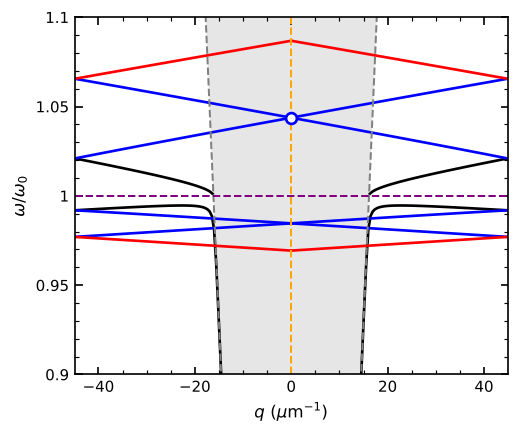

n = +-1 crossing at q = 0: w/w0 = 1.0437


In [8]:
def _kappa(w, q):
    return np.sqrt(q**2 - eps1 * w**2 / c**2 + 0j)


def _branch_inplane(w, q):
    return np.real(1 - _kappa(w, q) * Csix(w) / (2 * eps1))


def _branch_outplane(w, q):
    return np.real(-_kappa(w, q) + q**2 * Csiz(w) / (2 * epsb))


def _solve_band(q_values, func, w_lo, w_hi, n_scan=1500):
    """For each q, the root of func(w, q) in [w_lo, w_hi]; q without a bound mode are skipped."""
    wb, qb = [], []
    for q in q_values:
        wgrid = np.linspace(w_lo, w_hi, n_scan)
        vals = func(wgrid, q)
        roots = [brentq(func, wgrid[i], wgrid[i + 1], args=(q,), xtol=1e-10 * w0)
                 for i in range(n_scan - 1) if vals[i] * vals[i + 1] < 0]
        if roots:
            wb.append(roots[-1] if w_hi > w0 else roots[0])
            qb.append(q)
    return np.array(wb), np.array(qb)


configure(dpp_=0.0)                     # lossless
piR = np.pi / R
G = 2 * piR
# zones 1-4 of the out-of-plane branch, then zones 1-4 of the in-plane branch
# (q = 0 is excluded from the first out-of-plane zone, where the equation reduces to 0 = 0)
zones = [(0.005, 1, _branch_outplane, 0.01, 0.999995), (1, 2, _branch_outplane, 0.5, 0.999995),
         (2, 3, _branch_outplane, 0.5, 0.999995), (3, 4, _branch_outplane, 0.5, 0.999995),
         (0, 1, _branch_inplane, 1.000005, 1.3), (1, 2, _branch_inplane, 1.000005, 1.3),
         (2, 3, _branch_inplane, 1.000005, 1.3), (3, 4, _branch_inplane, 1.000005, 1.3)]
bands = [_solve_band(np.linspace(qa * piR, qb * piR, 100), f, wa * w0, wb * w0) for qa, qb, f, wa, wb in zones]
configure()

w_circle = bands[5][0][np.argmax(bands[5][1])]          # n = +-1 crossing at q = 0
wl = np.linspace(0.85 * w0, 1.15 * w0, 300)
ql = np.sqrt(eps1) * wl / c                            # grazing incidence

fig, ax = new_figure(FIG_WIDE)
ax.fill_betweenx(wl / w0, -ql / 1e6, ql / 1e6, color="0.90", lw=0, zorder=0)
for shift, colour, i in [(0, "black", 0), (0, "black", 4), (G, "blue", 1), (G, "blue", 2),
                         (G, "blue", 5), (G, "blue", 6), (2 * G, "red", 3), (2 * G, "red", 7)]:
    wb, qb = bands[i]
    ax.plot((qb - shift) / 1e6, wb / w0, color=colour)
    ax.plot((-qb + shift) / 1e6, wb / w0, color=colour)
ax.axvline(0.0, color="orange", ls="--", lw=1.2)
ax.plot(ql / 1e6, wl / w0, color="gray", ls="--", lw=1.2)
ax.plot(-ql / 1e6, wl / w0, color="gray", ls="--", lw=1.2)
ax.axhline(1.0, color="purple", ls="--", lw=1.2)
ax.plot(0.0, w_circle / w0, marker="o", markersize=6.5, mfc="white", mec="blue", mew=1.6, ls="", zorder=10)
ax.set_xlabel(r"$q\ (\mu\mathrm{m}^{-1})$")
ax.set_ylabel(r"$\omega/\omega_0$")
ax.set_xlim(-piR / 1e6, piR / 1e6)
ax.set_ylim(0.9, 1.1)
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:g}"))
save_figure(fig, "band_structure")
plt.show()
print("n = +-1 crossing at q = 0: w/w0 = %.4f" % (w_circle / w0))

## Figs. 3-5: grating period, angle of incidence, filling factor

All spectra are at normal incidence unless stated otherwise, and are evaluated only inside the plotted window.

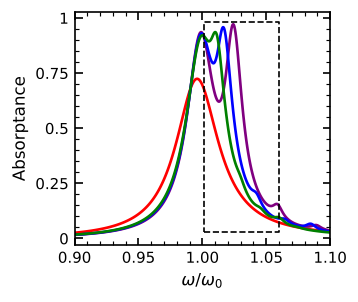

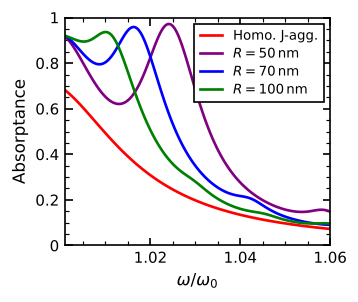

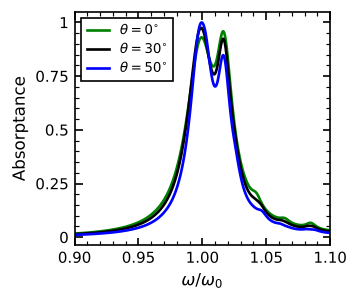

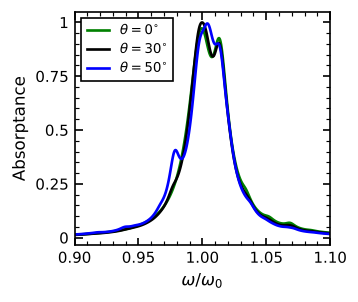

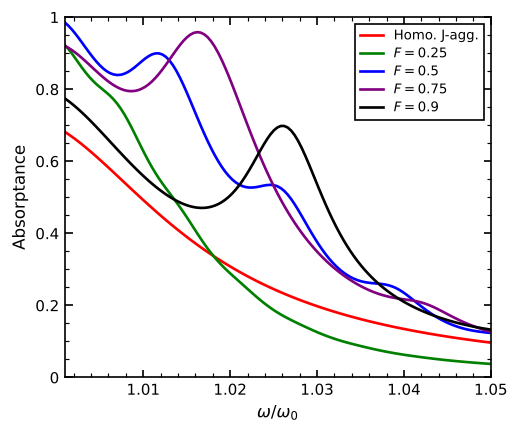

In [9]:
def plot_curves(curves, xw, size, xlim, ylim, name, legend_loc=None, zoom_box=None):
    fig, ax = new_figure(size)
    for A, colour, label in curves:
        ax.plot(xw, A, color=colour, label=label)
    if zoom_box is not None:                       # frame of the region shown in Fig. 3(b)
        (xa, ya), (xb, yb) = zoom_box
        ax.plot([xa, xb, xb, xa, xa], [ya, ya, yb, yb, ya], color="black", ls="--", lw=1.0)
    ax.set_xlabel(r"$\omega/\omega_0$")
    ax.set_ylabel("Absorptance")
    ax.set_xlim(*xlim)
    if ylim:
        ax.set_ylim(*ylim)
    if legend_loc:
        ax.legend(loc=legend_loc)
    ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:g}"))
    save_figure(fig, name)
    plt.show()


# Fig. 3: (a) full window, (b) zoom on the first-order SEP
for (lo, hi), ylim, name, loc, box in (
        ((0.9, 1.1), None, "Absorbance_for_different_R", None, ((1.001, 0.03), (1.06, 0.98))),
        ((1.001, 1.06), (0, 1), "Absorbance_for_different_R_zoom", "upper right", None)):
    wsw, xw = window(lo, hi)
    configure(homogeneous=True)
    curves = [(spectrum(wsw), "red", "Homo. J-agg.")]
    for R_nm, colour in ((50, "purple"), (70, "blue"), (100, "green")):
        configure(R_nm=R_nm)
        curves.append((spectrum(wsw), colour, r"$R = %d\,\mathrm{nm}$" % R_nm))
    plot_curves(curves, xw, FIG_PANEL, (lo, hi), ylim, name, loc, box)
configure()

# Fig. 4: angle of incidence for Psi = 15 and 30 deg
wsw, xw = window(0.9, 1.1)
for kasha, name in ((15, "Absorbance_for_different_angles"), (30, "Absorbance_for_different_angles_psi_30")):
    configure(kasha_deg=kasha)
    curves = [(spectrum(wsw, np.radians(th)), colour, r"$\theta = %d^{\circ}$" % th)
              for th, colour in ((0, "green"), (30, "black"), (50, "blue"))]
    plot_curves(curves, xw, FIG_PANEL, (0.9, 1.1), None, name, "upper left")
configure()

# Fig. 5: filling factor
wsw, xw = window(1.001, 1.05)
configure(homogeneous=True)
curves = [(spectrum(wsw), "red", "Homo. J-agg.")]
for fill, colour in ((0.25, "green"), (0.50, "blue"), (0.75, "purple"), (0.90, "black")):
    configure(fill=fill)
    curves.append((spectrum(wsw), colour, r"$F = %g$" % fill))
plot_curves(curves, xw, FIG_WIDE, (1.001, 1.05), (0, 1), "Absorbance_for_different_filling_factors", "upper right")
configure()

## Fig. 6: effect of the metallic mirror

Without the metal, region III is the same dielectric as the spacer.

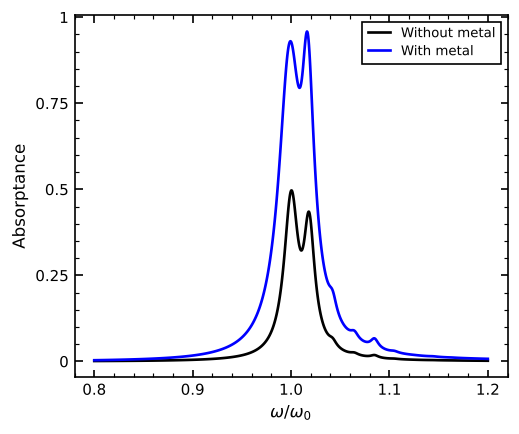

In [10]:
A_metal = spectrum(ws)
with without_metal():
    A_bare = spectrum(ws)

fig, ax = new_figure(FIG_WIDE)
ax.plot(x, A_bare, color="black", label="Without metal")
ax.plot(x, A_metal, color="blue", label="With metal")
ax.set_xlabel(r"$\omega/\omega_0$")
ax.set_ylabel("Absorptance")
ax.legend(loc="upper right")
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:g}"))
save_figure(fig, "Absorbance_with_and_without_metal")
plt.show()

## Fig. 7: spacer thickness

(a) Absorptance at $\omega=1.02\,\omega_0$ as a function of $d$; (b) spectra for three values of $d$.

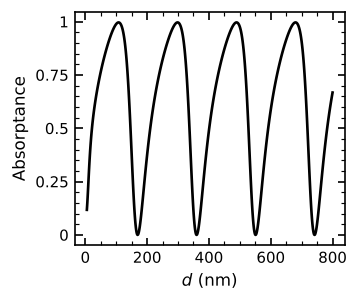

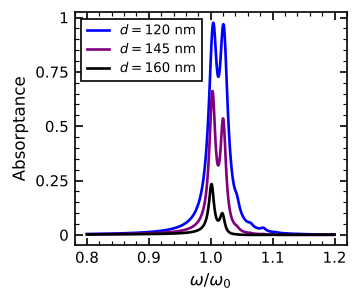

In [11]:
d_values = np.linspace(5, 800, 1000)
A_d = []
for d_nm in d_values:
    configure(d_nm=d_nm)
    A_d.append(absorptance(1.02 * w0))
configure()

fig, ax = new_figure(FIG_PANEL)
ax.plot(d_values, A_d, color="black")
ax.set_xlabel(r"$d\ (\mathrm{nm})$")
ax.set_ylabel("Absorptance")
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:g}"))
save_figure(fig, "Absorbance_for_different_values_of_d")
plt.show()

fig, ax = new_figure(FIG_PANEL)
for d_nm, colour in ((120, "blue"), (145, "purple"), (160, "black")):
    configure(d_nm=d_nm)
    ax.plot(x, spectrum(ws), color=colour, label=r"$d = %g\ \mathrm{nm}$" % d_nm)
configure()
ax.set_xlabel(r"$\omega/\omega_0$")
ax.set_ylabel("Absorptance")
ax.legend(loc="upper left")
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:g}"))
save_figure(fig, "Absorbance_for_different_d")
plt.show()

## Fig. 8: ultimate limit of the absorptance and losses in the metal

With the lossless metal and $R\ll\lambda$ only the specular order carries power, so $\mathcal{A}=1-|r_0|^2$ and
unit absorptance requires $r_0=0$, which can be met by tuning $\omega$ and $d$. The cell below maps
$\log_{10}(1-\mathcal{A}_\mathrm{J})$ over the $(\omega,d)$ plane for the lossless metal and for silver, refines every local
minimum by a joint minimisation over $(\omega,d)$, and takes cuts at the frequencies of the two resonances for
several damping rates of the metal. This is the slowest part of the notebook (a few minutes; less with `FAST`).

In [12]:
def one_minus_AJ(xv, d_nm, gamma_m_eV=0.0):
    configure(d_nm=d_nm)
    with (lossy_metal(gamma_m_eV) if gamma_m_eV else nullcontext()):
        return 1.0 - absorptance(xv * w0)


def optimise(x_start, d_start, gamma_m_eV=0.0, half_width=0.004):
    """Minimise 1 - A_J over (w/w0, d) around a starting point."""
    def cost(p):
        if abs(p[0] - x_start) > half_width or p[1] <= 1.0:
            return 1.0
        return one_minus_AJ(p[0], p[1], gamma_m_eV)
    r = minimize(cost, [x_start, d_start], method="Nelder-Mead",
                 options=dict(xatol=1e-11, fatol=1e-17, maxiter=4000))
    configure()
    return r.x[0], r.x[1], r.fun


def log_map(gamma_m_eV):
    L = np.array([[np.log10(max(one_minus_AJ(xv, dv, gamma_m_eV), 1e-16)) for xv in x_map] for dv in d_map])
    configure()
    return L


def best_points(L, threshold, gamma_m_eV):
    """Local minima of a map, each refined by optimise(); duplicates are dropped."""
    is_min = (L == minimum_filter(L, size=7, mode="nearest")) & (L < threshold)
    found = []
    for i, j in zip(*np.nonzero(is_min)):
        p = optimise(x_map[j], d_map[i], gamma_m_eV)
        if all(abs(p[0] - q[0]) > 1e-4 or abs(p[1] - q[1]) > 0.5 for q in found):
            found.append(p)
    return sorted(found)


x_map = np.linspace(0.99, 1.04, 70 if FAST else 150)
d_map = np.linspace(20, 220, 60 if FAST else 120)        # nm

L_lossless = log_map(0.0)
best_lossless = best_points(L_lossless, -1.5, 0.0)
L_silver = log_map(GAMMA_AG_EV)
best_silver = best_points(L_silver, -1.0, GAMMA_AG_EV)

print("lossless metal:")
for xs, ds, res in best_lossless:
    print("   w/w0 = %.5f, d = %6.2f nm, 1 - A = %.1e" % (xs, ds, res))
print("silver:")
for xs, ds, res in best_silver:
    configure(d_nm=ds)
    with lossy_metal(GAMMA_AG_EV):
        _, Am, AJ = power_balance(xs * w0)
    print("   w/w0 = %.5f, d = %6.2f nm, A_J = %.4f, A_m = %.4f" % (xs, ds, AJ, Am))
configure()

with oscillator_strength(11e-9):         # a 10% larger f0 brings the first-order SEP to A = 1
    print("f0 = 11 nm, first-order SEP: w/w0 = %.5f, d = %.2f nm, 1 - A = %.1e"
          % optimise(1.021, 106.0, half_width=0.01))

print("first-order SEP at d = 60 nm:")
wsw, xw = window(1.006, 1.04)
for gm in (0.0, GAMMA_AG_EV, 0.05, 0.10):
    with (lossy_metal(gm) if gm else nullcontext()):
        rows = np.array([power_balance(w) for w in wsw])
    i = int(np.argmax(rows[:, 2]))
    print("   hbar*gamma_m = %.3f eV: A_J = %.4f, A_m = %.4f at w/w0 = %.4f" % (gm, rows[i, 2], rows[i, 1], xw[i]))

lossless metal:
   w/w0 = 0.99592, d =  27.14 nm, 1 - A = 1.1e-16
   w/w0 = 0.99592, d = 222.62 nm, 1 - A = 0.0e+00
   w/w0 = 1.00436, d = 107.19 nm, 1 - A = 2.2e-16
   w/w0 = 1.01838, d =  96.02 nm, 1 - A = 1.3e-04
silver:
   w/w0 = 0.99594, d =  27.34 nm, A_J = 0.9971, A_m = 0.0029
   w/w0 = 0.99594, d = 222.81 nm, A_J = 0.9971, A_m = 0.0029
   w/w0 = 1.00434, d = 107.04 nm, A_J = 0.9981, A_m = 0.0019
   w/w0 = 1.01821, d =  94.45 nm, A_J = 0.9982, A_m = 0.0017


f0 = 11 nm, first-order SEP: w/w0 = 1.02143, d = 106.24 nm, 1 - A = 5.6e-16
first-order SEP at d = 60 nm:


   hbar*gamma_m = 0.000 eV: A_J = 0.9586, A_m = 0.0000 at w/w0 = 1.0162


   hbar*gamma_m = 0.018 eV: A_J = 0.9570, A_m = 0.0017 at w/w0 = 1.0162


   hbar*gamma_m = 0.050 eV: A_J = 0.9543, A_m = 0.0048 at w/w0 = 1.0162


   hbar*gamma_m = 0.100 eV: A_J = 0.9501, A_m = 0.0096 at w/w0 = 1.0162


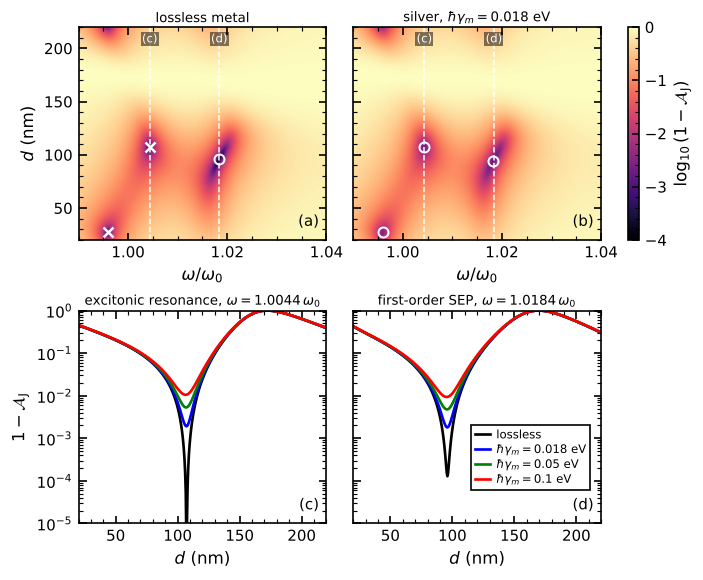

In [13]:
# cuts at the frequency of the excitonic zero near d = 107 nm and of the first-order SEP optimum
cut_exc = [p for p in best_lossless if 1.0 < p[0] < 1.012 and 50 < p[1] < 150][0]
cut_sep = [p for p in best_lossless if p[0] > 1.012][0]
CUTS = {"c": ("excitonic resonance", cut_exc[0]), "d": ("first-order SEP", cut_sep[0])}
GAMMAS = (0.0, GAMMA_AG_EV, 0.05, 0.10)

d_cut = np.unique(np.concatenate([np.linspace(20, 220, 401), [cut_exc[1], cut_sep[1]]]))
SLICE = {(key, gm): np.array([max(one_minus_AJ(xc, dd, gm), 1e-16) for dd in d_cut])
         for key, (_, xc) in CUTS.items() for gm in GAMMAS}
configure()

fig = plt.figure(figsize=(146 * MM, 120 * MM), layout="constrained")
axd = fig.subplot_mosaic([["a", "b"], ["c", "d"]])
for key, L, title in (("a", L_lossless, "lossless metal"),
                      ("b", L_silver, r"silver, $\hbar\gamma_m = %.3f$ eV" % GAMMA_AG_EV)):
    ax = axd[key]
    mesh = ax.pcolormesh(x_map, d_map, L, shading="gouraud", cmap="magma", vmin=-4, vmax=0, rasterized=True)
    for ckey, (_, xc) in CUTS.items():
        ax.axvline(xc, color="white", ls="--", lw=0.9)
        ax.text(xc, 214, "(%s)" % ckey, color="white", fontsize=7, ha="center", va="top",
                bbox=dict(boxstyle="square,pad=0.1", fc="black", ec="none", alpha=0.5))
    ax.set_xlabel(r"$\omega/\omega_0$")
    ax.set_title(title, fontsize=8, pad=3)
    ax.text(0.97, 0.05, "(%s)" % key, transform=ax.transAxes, fontsize=9, ha="right", va="bottom")
for xs, ds, res in best_lossless:
    if ds <= d_map[-1]:
        style = dict(marker="x", color="white", mew=1.5) if res < 1e-10 else dict(marker="o", mfc="none", mec="white", mew=1.2)
        axd["a"].plot(xs, ds, ms=6, ls="", **style)
for xs, ds, res in best_silver:
    if ds <= d_map[-1]:
        axd["b"].plot(xs, ds, marker="o", mfc="none", mec="white", ms=6, mew=1.2, ls="")
axd["a"].set_ylabel(r"$d\ (\mathrm{nm})$")
axd["b"].tick_params(labelleft=False)
cbar = fig.colorbar(mesh, ax=[axd["a"], axd["b"]], pad=0.02)
cbar.set_label(r"$\log_{10}(1-\mathcal{A}_{\mathrm{J}})$")
cbar.outline.set_linewidth(1.0)

for key, (name, xc) in CUTS.items():
    ax = axd[key]
    for gm, colour in zip(GAMMAS, ("black", "blue", "green", "red")):
        ax.semilogy(d_cut, SLICE[key, gm], color=colour,
                    label="lossless" if gm == 0 else r"$\hbar\gamma_m = %g$ eV" % gm)
    ax.set_xlim(d_map[0], d_map[-1])
    ax.set_ylim(1e-5, 1)
    ax.set_xlabel(r"$d\ (\mathrm{nm})$")
    ax.set_title(r"%s, $\omega = %.4f\,\omega_0$" % (name, xc), fontsize=8, pad=3)
    ax.text(0.97, 0.05, "(%s)" % key, transform=ax.transAxes, fontsize=9, ha="right", va="bottom")
axd["c"].set_ylabel(r"$1-\mathcal{A}_{\mathrm{J}}$")
axd["d"].tick_params(labelleft=False)
axd["d"].legend(loc="lower right", bbox_to_anchor=(0.98, 0.13), fontsize=7,
                handlelength=1.3, handletextpad=0.5, labelspacing=0.25, borderpad=0.35)
save_figure(fig, "Absorptance_limit_lossy_metal")
plt.show()

## Additional results from the reply to the referees

Not shown in the paper.

**Strongly tilted dipoles** ($\Psi=50^\circ$, Fig. R1 of the reply). The out-of-plane SEP branch gives an absorption
peak below $\omega_0$ that is absent at normal incidence.

theta =  0 deg, peaks (w/w0, A): [(0.9998, 0.991)]


theta = 30 deg, peaks (w/w0, A): [(0.9449, 0.304), (1.0026, 0.964)]


theta = 50 deg, peaks (w/w0, A): [(0.9217, 0.128), (0.9489, 0.73), (1.0094, 0.99)]


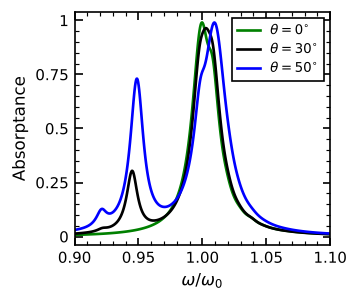

In [14]:
wsw, xw = window(0.9, 1.1)
configure(kasha_deg=50)
fig, ax = new_figure(FIG_PANEL)
for th, colour in ((0, "green"), (30, "black"), (50, "blue")):
    A = spectrum(wsw, np.radians(th))
    ax.plot(xw, A, color=colour, label=r"$\theta = %d^{\circ}$" % th)
    pk, _ = find_peaks(A)
    print("theta = %2d deg, peaks (w/w0, A):" % th,
          [(round(float(xw[i]), 4), round(float(A[i]), 3)) for i in pk if A[i] > 0.05])
configure()
ax.set_xlabel(r"$\omega/\omega_0$")
ax.set_ylabel("Absorptance")
ax.set_xlim(0.9, 1.1)
ax.legend(loc="upper right")
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:g}"))
save_figure(fig, "Absorbance_for_different_angles_psi_50")
plt.show()

**Air superstrate** ($\varepsilon_1=1$, $\varepsilon_2=2.3$). Without the mirror the absorptance is bounded by
$\sqrt{\varepsilon_1}/(\sqrt{\varepsilon_1}+\sqrt{\varepsilon_2})$ instead of $1/2$; with the mirror it can still reach unity.

In [15]:
def first_sep(A, xw):
    pk, _ = find_peaks(A)
    i = [i for i in pk if xw[i] > 1.006 and A[i] > 0.05][0]
    return xw[i], A[i]


wsw, xw = window(0.9, 1.1)
for e1 in (2.3, 1.0):
    with superstrate(e1):
        A_mirror = spectrum(wsw)
        with without_metal():
            A_free = spectrum(wsw)
    xs, As = first_sep(A_mirror, xw)
    x_sep = xs
    print("eps1 = %.1f: first-order SEP at w/w0 = %.4f, A = %.4f (d = 60 nm); "
          "without metal max A = %.4f, bound %.4f"
          % (e1, xs, As, A_free.max(), np.sqrt(e1) / (np.sqrt(e1) + np.sqrt(eps2))))
with superstrate(1.0):                  # start from the peak at d = 60 nm
    xs, ds, res = optimise(x_sep, 108.0, half_width=0.012)
print("eps1 = 1.0, optimum of the first-order SEP: w/w0 = %.5f, d = %.2f nm, 1 - A = %.1e" % (xs, ds, res))

eps1 = 2.3: first-order SEP at w/w0 = 1.0162, A = 0.9586 (d = 60 nm); without metal max A = 0.4968, bound 0.5000


eps1 = 1.0: first-order SEP at w/w0 = 1.0222, A = 0.9855 (d = 60 nm); without metal max A = 0.3973, bound 0.3974


eps1 = 1.0, optimum of the first-order SEP: w/w0 = 1.02886, d = 108.37 nm, 1 - A = 3.3e-15


**Homogeneous sheet: closed form.** At normal incidence an unpatterned sheet above the mirror has
$r=(n_1-s-Y_L)/(n_1+s+Y_L)$, with the sheet admittance $s=-i(\omega/c)\chi_\parallel$ and the admittance of the
spacer terminated by the metal $Y_L=n_2(1-r_m e^{2ik_2d})/(1+r_m e^{2ik_2d})$, $r_m=(n_2-n_3)/(n_2+n_3)$. For a
lossless metal $Y_L$ is imaginary, so $\mathcal{A}=1$ if and only if $\mathrm{Re}\,s(\omega)=n_1$ (with $d$ chosen such that
$\mathrm{Im}\,Y_L=-\mathrm{Im}\,s$). The cell checks the closed form against the matrix calculation and evaluates both at the
two frequencies where $\mathrm{Re}\,s=n_1$. For a lossy metal, at total absorption the metal takes the fraction
$\mathrm{Re}\,Y_L/n_1$, which is compared with $\mathcal{A}_\mathrm{m}$ at the optima of Fig. 8(b).

In [16]:
def sheet_admittance(w):
    return -1j * (w / c) * (-Csix(w))


def load_admittance(w, d_value):
    n2, n3 = np.sqrt(eps2), np.sqrt(epsmetal(w) + 0j)
    rm = (n2 - n3) / (n2 + n3)
    ph = np.exp(2j * n2 * w / c * d_value)
    return n2 * (1 - rm * ph) / (1 + rm * ph)


def A_closed_form(w, d_value):
    n1, s, YL = np.sqrt(eps1), sheet_admittance(w), load_admittance(w, d_value)
    return 1 - abs((n1 - s - YL) / (n1 + s + YL))**2


wsw, xw = window(0.9, 1.1)
configure(homogeneous=True)
print("max |A_matrix - A_closed_form| at d = 60 nm: %.1e"
      % np.max(np.abs(spectrum(wsw) - [A_closed_form(w, d) for w in wsw])))
print("peak Re s = %.3f, n1 = %.3f" % ((w0 / c) * f0 * w0 * np.cos(b)**2 / (4 * dpp), np.sqrt(eps1)))

for lo, hi in ((0.95, 0.99999), (1.00001, 1.05)):
    w_star = brentq(lambda w: sheet_admittance(w).real - np.sqrt(eps1), lo * w0, hi * w0)
    half_wl = np.pi * c / (w_star * np.sqrt(eps2))
    dg = np.linspace(0.2e-9, half_wl, 4000)
    j = int(np.argmin([1 - A_closed_form(w_star, dd) for dd in dg]))
    res = minimize_scalar(lambda dd: 1 - A_closed_form(w_star, dd), bounds=(dg[max(j - 1, 0)], dg[min(j + 1, 3999)]),
                          method="bounded", options=dict(xatol=1e-16))
    configure(homogeneous=True, d_nm=res.x * 1e9)
    print("Re s = n1 at w/w0 = %.5f, d = %.2f nm: 1 - A = %.1e (closed form), %.1e (matrix)"
          % (w_star / w0, res.x * 1e9, res.fun, 1 - absorptance(w_star)))
configure()

with lossy_metal(GAMMA_AG_EV):
    for xs, ds, _ in best_silver:
        if ds <= d_map[-1]:
            configure(d_nm=ds)
            print("silver optimum w/w0 = %.5f: Re Y_L / n1 = %.4f, A_m = %.4f"
                  % (xs, load_admittance(xs * w0, ds * 1e-9).real / np.sqrt(eps1), power_balance(xs * w0)[1]))
configure()

max |A_matrix - A_closed_form| at d = 60 nm: 3.9e-08
peak Re s = 5.213, n1 = 1.517
Re s = n1 at w/w0 = 0.99259, d = 13.97 nm: 1 - A = 0.0e+00 (closed form), 7.8e-16 (matrix)
Re s = n1 at w/w0 = 1.00746, d = 136.59 nm: 1 - A = 0.0e+00 (closed form), 1.2e-15 (matrix)
silver optimum w/w0 = 0.99594: Re Y_L / n1 = 0.0029, A_m = 0.0029
silver optimum w/w0 = 1.00434: Re Y_L / n1 = 0.0019, A_m = 0.0019
silver optimum w/w0 = 1.01821: Re Y_L / n1 = 0.0016, A_m = 0.0017
